### IceCube healpix map generation

This notebooks can generate an IceCube (IC) healpix alert map at any given sky position [ra, dec] and time. The output is in the same format as the real IC alerts and can be read as input in all the RubiCube analysis noetbooks and ampel job files

The goal for this is to be able to test if we can read in Rubin alerts from an IC alert map. The general steps to do so:
1. Obtain the positions of Rubin alerts that pass our filters 
2. Generate an IC map at that time and position -> Done
3. Check if the healpxToken generator works for the Rubin alert stream with a simple job file -> TO DO
    * We would need to adapt the job file `Rubicube/ampel job files/TEST_ic_alert_ZTF_processor.yaml`. I;m not sure if the alerts require the same HealpixToken generator object as input to be able to query pixel areas. 


Note: map takes 1-2 min to generate roughly

In [1]:
from astropy.time import Time
import astropy.units as u

from ic_map_generator import generate_map

import sys
sys.path.insert(1, '/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube/')
#we need the path to our IC plotting and processing functions
from ic_visualization import plot_full_map
from ic_processing import read_map



/Users/cristozilleruelo/.local/share/mamba/envs/AMPEL/lib/python3.14/site-packages/ligo/skymap/io/events/ligolw.py:26: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


In [4]:
IC_alert =  {
    'name': 'TEST',
    'ra': 200,
    'dec': 0,
    'ra_dec_error': 0.5, #average spread
    't_mjd': Time("2026-11-19"),
    'stream': 'GOLD',
    }

In [6]:

m_sim, m_path = generate_map(alert=IC_alert, 
                             nside=512,
                             save_path='IC_test.fits')

Now we can read the map using the same methods as for the real alerts

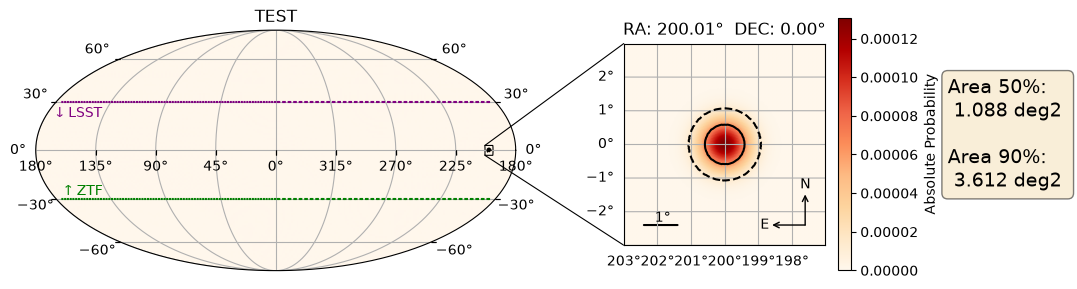

In [7]:
skymap = read_map(m_path, 
                add_units=True) #This just adds 1/sr to the simulated map
_ = plot_full_map(skymap, save_dir='')